In [8]:
import sys
print(sys.executable)

c:\breastcancer-ai\.venv\Scripts\python.exe


In [9]:
import sys
import numpy as np
import pandas as pd
import sklearn
from sklearn.datasets import load_breast_cancer

print("Python:", sys.executable)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)

print("\nPython environment is working!")

# Load the breast cancer dataset
data = load_breast_cancer(as_frame=True)

print("\nDataset loaded successfully!")
print("Dataset shape:", data.data.shape)
print("Number of features:", len(data.feature_names))
print("Target classes:", data.target_names)

Python: c:\breastcancer-ai\.venv\Scripts\python.exe
NumPy: 2.2.6
Pandas: 2.3.3
Scikit-learn: 1.7.2

Python environment is working!

Dataset loaded successfully!
Dataset shape: (569, 30)
Number of features: 30
Target classes: ['malignant' 'benign']


In [10]:
# Check the dataset dimensions
print("Dataset shape:", data.frame.shape)

# Display the first 5 records
display(data.frame.head())

# Display the last 5 records
display(data.frame.tail())

Dataset shape: (569, 31)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
564,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,0.05623,...,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115,0
565,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,0.05533,...,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637,0
566,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,0.05648,...,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820,0
567,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,0.2397,0.07016,...,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400,0
568,7.76,24.54,47.92,181.0,0.05263,0.04362,0.00000,0.00000,0.1587,0.05884,...,30.37,59.16,268.6,0.08996,0.06444,0.0000,0.0000,0.2871,0.07039,1


In [11]:
# Display the class names
print("Target names:", data.target_names)

# Count the number of records in each class
print("\nClass distribution:")
print(data.target.value_counts().sort_index())

# Add readable labels
df = data.frame.copy()

df["target_label"] = df["target"].map({
    0: "malignant",
    1: "benign"
})

print("\nUpdated dataset shape:", df.shape)
display(df[["target", "target_label"]].head())

Target names: ['malignant' 'benign']

Class distribution:
target
0    212
1    357
Name: count, dtype: int64

Updated dataset shape: (569, 32)


,target,target_label
0,0,malignant
1,0,malignant
2,0,malignant
3,0,malignant
4,0,malignant


In [12]:
from pathlib import Path

# Define the project folder
project_root = Path(r"C:\breastcancer-ai")

# Define the CSV file location
csv_path = project_root / "data" / "raw" / "wdbc.csv"

# Create the folder if it doesn't exist
csv_path.parent.mkdir(parents=True, exist_ok=True)

# Save the dataset
df.to_csv(csv_path, index=False)

print("Dataset saved successfully!")
print("File location:", csv_path)
print("File size:", round(csv_path.stat().st_size / 1024, 2), "KB")

Dataset saved successfully!
File location: C:\breastcancer-ai\data\raw\wdbc.csv
File size: 123.62 KB


In [13]:
from pathlib import Path
import pandas as pd

# Locate the saved dataset
csv_path = Path(r"C:\breastcancer-ai\data\raw\wdbc.csv")

# Load the saved CSV
df_check = pd.read_csv(csv_path)

# Verify the dataset
print("File exists:", csv_path.exists())
print("Dataset shape:", df_check.shape)
print("Missing values:", df_check.isnull().sum().sum())
print("Duplicate rows:", df_check.duplicated().sum())

# Verify the target labels
print("\nTarget distribution:")
print(df_check["target"].value_counts().sort_index())

# Final checks
assert csv_path.exists(), "Dataset file not found!"
assert df_check.shape == (569, 32), "Unexpected dataset shape!"
assert df_check.isnull().sum().sum() == 0, "Missing values found!"
assert set(df_check["target"].unique()) == {0, 1}, "Unexpected target labels!"

print("\nSUCCESS: All dataset verification checks passed!")

File exists: True
Dataset shape: (569, 32)
Missing values: 0
Duplicate rows: 0

Target distribution:
target
0    212
1    357
Name: count, dtype: int64

SUCCESS: All dataset verification checks passed!


In [14]:
# Get the dataset's 30 input feature names
feature_columns = list(data.feature_names)

print("Total input features:", len(feature_columns))
print("\nAll 30 features:\n")

for number, feature in enumerate(feature_columns, start=1):
    print(f"{number:2}. {feature}")

Total input features: 30

All 30 features:

 1. mean radius
 2. mean texture
 3. mean perimeter
 4. mean area
 5. mean smoothness
 6. mean compactness
 7. mean concavity
 8. mean concave points
 9. mean symmetry
10. mean fractal dimension
11. radius error
12. texture error
13. perimeter error
14. area error
15. smoothness error
16. compactness error
17. concavity error
18. concave points error
19. symmetry error
20. fractal dimension error
21. worst radius
22. worst texture
23. worst perimeter
24. worst area
25. worst smoothness
26. worst compactness
27. worst concavity
28. worst concave points
29. worst symmetry
30. worst fractal dimension


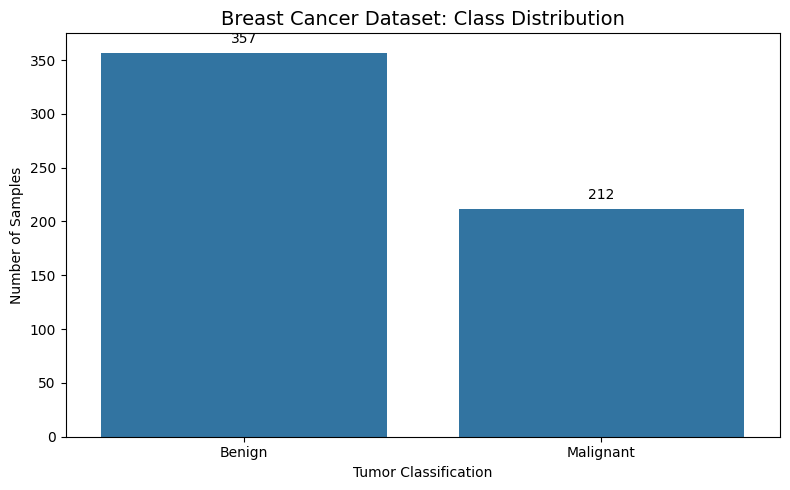

Chart saved to: C:\breastcancer-ai\data\raw\class_distribution.png


In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create readable labels for the target
df["target_label"] = df["target"].map({
    0: "Malignant",
    1: "Benign"
})

# Count each class
class_counts = df["target_label"].value_counts().reindex(
    ["Benign", "Malignant"]
)

# Create the chart
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=class_counts.index,
    y=class_counts.values
)

# Add values above the bars
for container in ax.containers:
    ax.bar_label(container, fmt="%d", padding=5)

plt.title("Breast Cancer Dataset: Class Distribution", fontsize=14)
plt.xlabel("Tumor Classification")
plt.ylabel("Number of Samples")
plt.tight_layout()

# Save the chart
chart_path = Path(r"C:\breastcancer-ai\data\raw\class_distribution.png")
plt.savefig(chart_path, dpi=300, bbox_inches="tight")

plt.show()

print("Chart saved to:", chart_path)

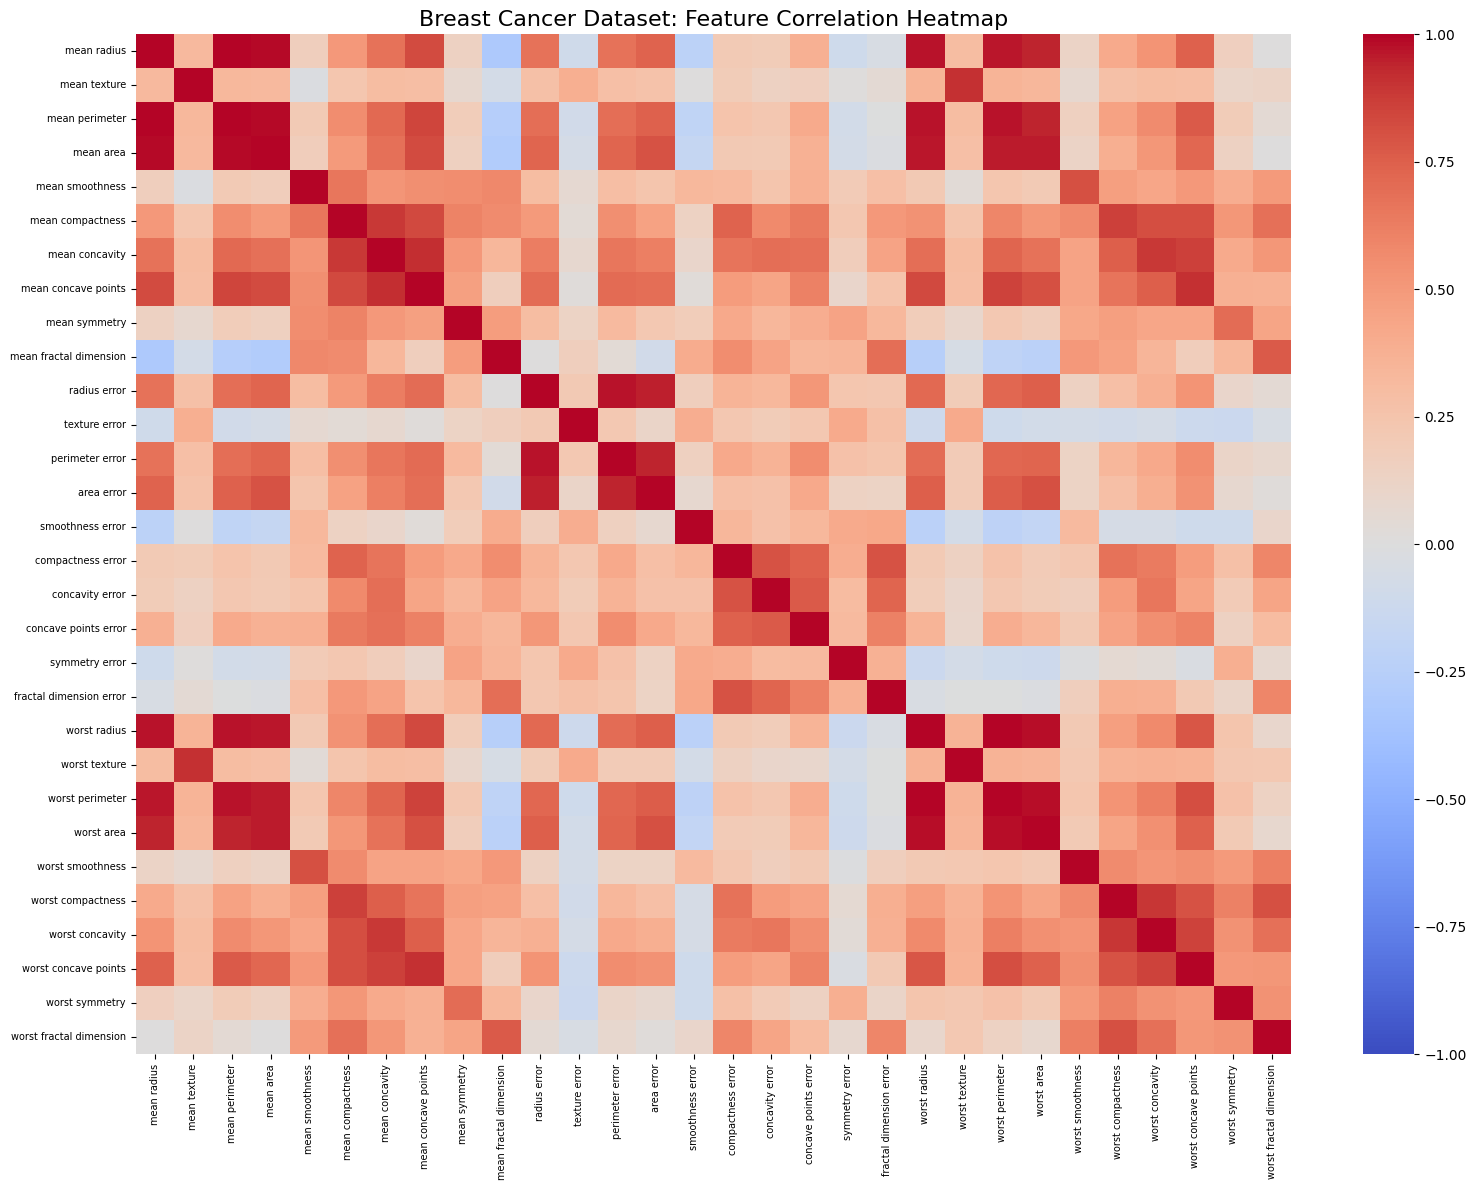

Heatmap saved to: C:\breastcancer-ai\data\raw\correlation_heatmap.png


In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select only the 30 numerical input features
X = df[feature_columns]

# Calculate correlations between features
correlation_matrix = X.corr()

# Create the heatmap
plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    xticklabels=True,
    yticklabels=True
)

plt.title("Breast Cancer Dataset: Feature Correlation Heatmap", fontsize=16)
plt.xticks(rotation=90, fontsize=7)
plt.yticks(rotation=0, fontsize=7)
plt.tight_layout()

# Save the chart
heatmap_path = Path(
    r"C:\breastcancer-ai\data\raw\correlation_heatmap.png"
)

plt.savefig(heatmap_path, dpi=300, bbox_inches="tight")
plt.show()

print("Heatmap saved to:", heatmap_path)

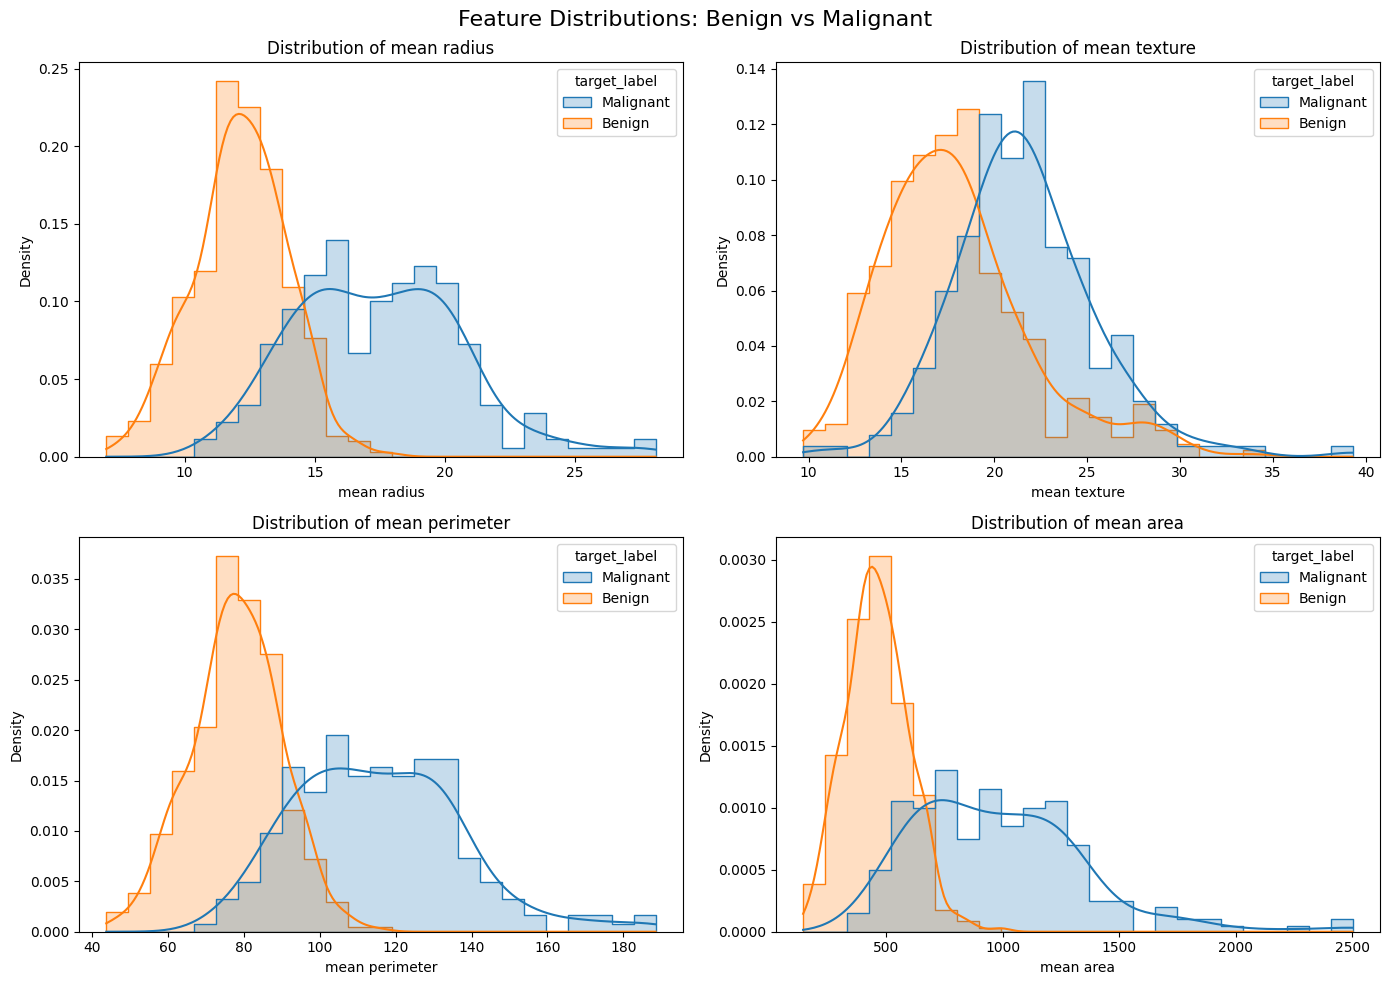

Charts saved to: C:\breastcancer-ai\data\raw\feature_distributions.png


In [17]:
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Add readable class labels
df["target_label"] = df["target"].map({
    0: "Malignant",
    1: "Benign"
})

# Features to compare
selected_features = [
    "mean radius",
    "mean texture",
    "mean perimeter",
    "mean area"
]

# Create a 2 x 2 grid of distribution plots
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for feature, ax in zip(selected_features, axes.flatten()):
    sns.histplot(
        data=df,
        x=feature,
        hue="target_label",
        bins=25,
        kde=True,
        element="step",
        stat="density",
        common_norm=False,
        ax=ax
    )

    ax.set_title(f"Distribution of {feature}")
    ax.set_ylabel("Density")

plt.suptitle(
    "Feature Distributions: Benign vs Malignant",
    fontsize=16
)

plt.tight_layout()

# Save the figure
distribution_path = Path(
    r"C:\breastcancer-ai\data\raw\feature_distributions.png"
)

plt.savefig(distribution_path, dpi=300, bbox_inches="tight")
plt.show()

print("Charts saved to:", distribution_path)

In [18]:
# Input features: the 30 numerical measurements
X = df[feature_columns].copy()

# Target labels: 0 = malignant, 1 = benign
y = df["target"].copy()

print("Input data shape:", X.shape)
print("Target data shape:", y.shape)

print("\nInput feature count:", X.shape[1])
print("\nTarget distribution:")
print(y.value_counts().sort_index())

Input data shape: (569, 30)
Target data shape: (569,)

Input feature count: 30

Target distribution:
target
0    212
1    357
Name: count, dtype: int64


In [19]:
from sklearn.model_selection import train_test_split

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("\nTraining class distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting class distribution:")
print(y_test.value_counts().sort_index())

Training samples: 455
Testing samples: 114

Training data shape: (455, 30)
Testing data shape: (114, 30)

Training class distribution:
target
0    170
1    285
Name: count, dtype: int64

Testing class distribution:
target
0    42
1    72
Name: count, dtype: int64


In [20]:
# Verify the split
assert len(X_train) + len(X_test) == len(X)
assert X_train.shape[1] == 30
assert X_test.shape[1] == 30
assert len(y_train) == len(X_train)
assert len(y_test) == len(X_test)

# Check for overlapping sample indices
assert set(X_train.index).isdisjoint(set(X_test.index))

print("SUCCESS: Dataset split verified!")
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Input features:", X_train.shape[1])

SUCCESS: Dataset split verified!
Training samples: 455
Testing samples: 114
Input features: 30


In [21]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

print("Machine learning libraries imported successfully!")

Machine learning libraries imported successfully!


In [22]:
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=5000))
    ]),

    "Random Forest": Pipeline([
        ("model", RandomForestClassifier(
            n_estimators=200,
            random_state=42
        ))
    ]),

    "Support Vector Machine": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC())
    ])
}

print("Models created:", list(models.keys()))

Models created: ['Logistic Regression', 'Random Forest', 'Support Vector Machine']


In [23]:
trained_models = {}

for name, model in models.items():
    print(f"Training {name}...")

    model.fit(X_train, y_train)
    trained_models[name] = model

    print(f"{name} trained successfully!\n")

print("All three models have been trained!")

Training Logistic Regression...
Logistic Regression trained successfully!

Training Random Forest...
Random Forest trained successfully!

Training Support Vector Machine...
Support Vector Machine trained successfully!

All three models have been trained!


In [24]:
for name, model in trained_models.items():
    predictions = model.predict(X_test)

    print(f"{name}:")
    print("  Predictions generated:", len(predictions))
    print("  First 5 predictions:", predictions[:5])
    print()

Logistic Regression:
  Predictions generated: 114
  First 5 predictions: [0 1 0 1 0]

Random Forest:
  Predictions generated: 114
  First 5 predictions: [0 1 0 0 0]

Support Vector Machine:
  Predictions generated: 114
  First 5 predictions: [0 1 0 1 0]



In [25]:
print("Shape (rows, columns):", df.shape)
print("\nFirst 5 rows:")
display(df.head())
print("\nLast 5 rows:")
display(df.tail())

Shape (rows, columns): (569, 32)

First 5 rows:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target,target_label
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0,Malignant
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0,Malignant
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0,Malignant
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0,Malignant
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0,Malignant



Last 5 rows:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target,target_label
564,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,0.05623,...,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115,0,Malignant
565,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,0.05533,...,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637,0,Malignant
566,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,0.05648,...,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820,0,Malignant
567,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,0.2397,0.07016,...,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400,0,Malignant
568,7.76,24.54,47.92,181.0,0.05263,0.04362,0.00000,0.00000,0.1587,0.05884,...,59.16,268.6,0.08996,0.06444,0.0000,0.0000,0.2871,0.07039,1,Benign


In [26]:
counts = df["target_label"].value_counts()
percent = df["target_label"].value_counts(normalize=True).mul(100).round(1)
summary = pd.DataFrame({"count": counts, "percent": percent})
display(summary)
print("\nRaw target codes:")
print(df["target"].value_counts().sort_index())

,count,percent
target_label,,
Benign,357,62.7
Malignant,212,37.3



Raw target codes:
target
0    212
1    357
Name: count, dtype: int64


In [27]:
reloaded = pd.read_csv(csv_path)

assert reloaded.shape == df.shape, "Shape mismatch after reloading"
assert len(feature_columns) == 30, "Expected 30 features"
assert set(reloaded["target"].unique()) == {0, 1}, "Unexpected target values"
assert reloaded[feature_columns].isna().sum().sum() == 0, "Missing values found"

print("All Phase 1 checks passed.")
print("Rows:", len(reloaded), "| Features:", len(feature_columns))

All Phase 1 checks passed.
Rows: 569 | Features: 30


In [28]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["figure.figsize"] = (8, 5)

# Colors we'll use consistently: teal = benign, pink/red = malignant
COLORS = {"Benign": "#14b8a6", "Malignant": "#e11d74"}

In [29]:
print("Missing values (total):", df.isna().sum().sum())
print("Duplicate rows (features only):", df[feature_columns].duplicated().sum())
print("Duplicate rows (all columns):", df.duplicated().sum())

print("\nAll feature columns numeric?",
      all(pd.api.types.is_numeric_dtype(df[c]) for c in feature_columns))
print("Unique target values:", sorted(df["target"].unique()))

Missing values (total): 0
Duplicate rows (features only): 0
Duplicate rows (all columns): 0

All feature columns numeric? True
Unique target values: [np.int64(0), np.int64(1)]


In [30]:
features = df[feature_columns]

print("Any infinite values?", np.isinf(features).any().any())
print("Any negative values?", (features < 0).any().any())

# Zeros are suspicious for some measurements. Let's see where they occur.
zero_counts = (features == 0).sum()
print("\nColumns containing zeros:")
print(zero_counts[zero_counts > 0])

Any infinite values? False
Any negative values? False

Columns containing zeros:
mean concavity          13
mean concave points     13
concavity error         13
concave points error    13
worst concavity         13
worst concave points    13
dtype: int64


In [31]:
display(features.describe().T[["min", "mean", "max"]].round(4))

,min,mean,max
mean radius,6.9810,14.1273,28.1100
mean texture,9.7100,19.2896,39.2800
mean perimeter,43.7900,91.9690,188.5000
mean area,143.5000,654.8891,2501.0000
mean smoothness,0.0526,0.0964,0.1634
mean compactness,0.0194,0.1043,0.3454
mean concavity,0.0000,0.0888,0.4268
mean concave points,0.0000,0.0489,0.2012
mean symmetry,0.1060,0.1812,0.3040
mean fractal dimension,0.0500,0.0628,0.0974


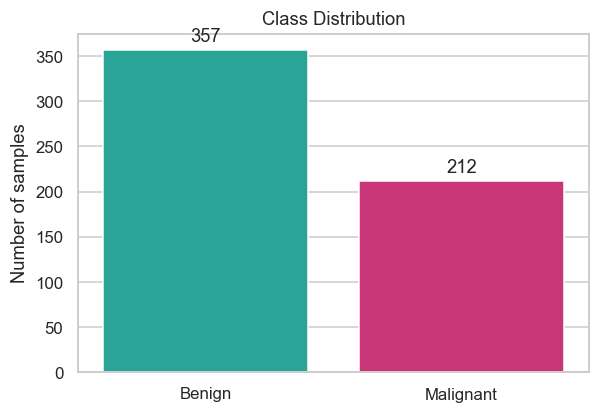

In [32]:
fig, ax = plt.subplots(figsize=(6, 4))
order = ["Benign", "Malignant"]
sns.countplot(data=df, x="target_label", order=order,
              palette=COLORS, hue="target_label", legend=False, ax=ax)
for container in ax.containers:
    ax.bar_label(container, padding=3)
ax.set_title("Class Distribution")
ax.set_xlabel("")
ax.set_ylabel("Number of samples")
plt.show()

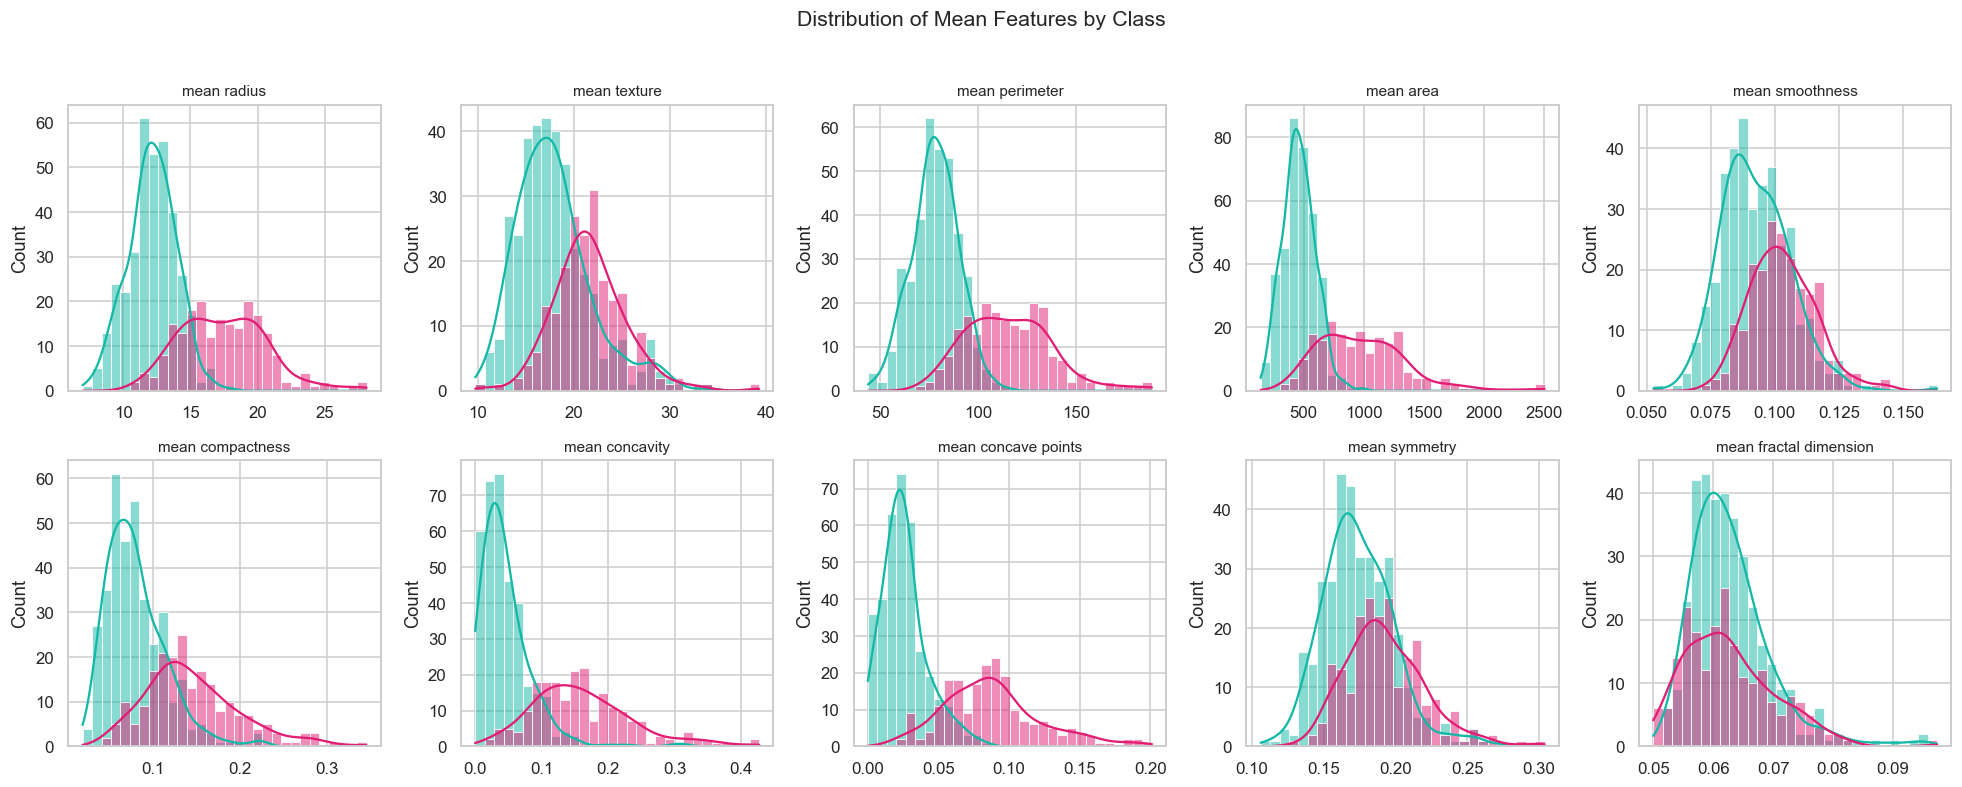

In [33]:
mean_cols = [c for c in feature_columns if c.startswith("mean ")]

fig, axes = plt.subplots(2, 5, figsize=(18, 7))
for ax, col in zip(axes.ravel(), mean_cols):
    sns.histplot(data=df, x=col, hue="target_label", palette=COLORS,
                 bins=30, kde=True, ax=ax, legend=False)
    ax.set_title(col, fontsize=10)
    ax.set_xlabel("")
fig.suptitle("Distribution of Mean Features by Class", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

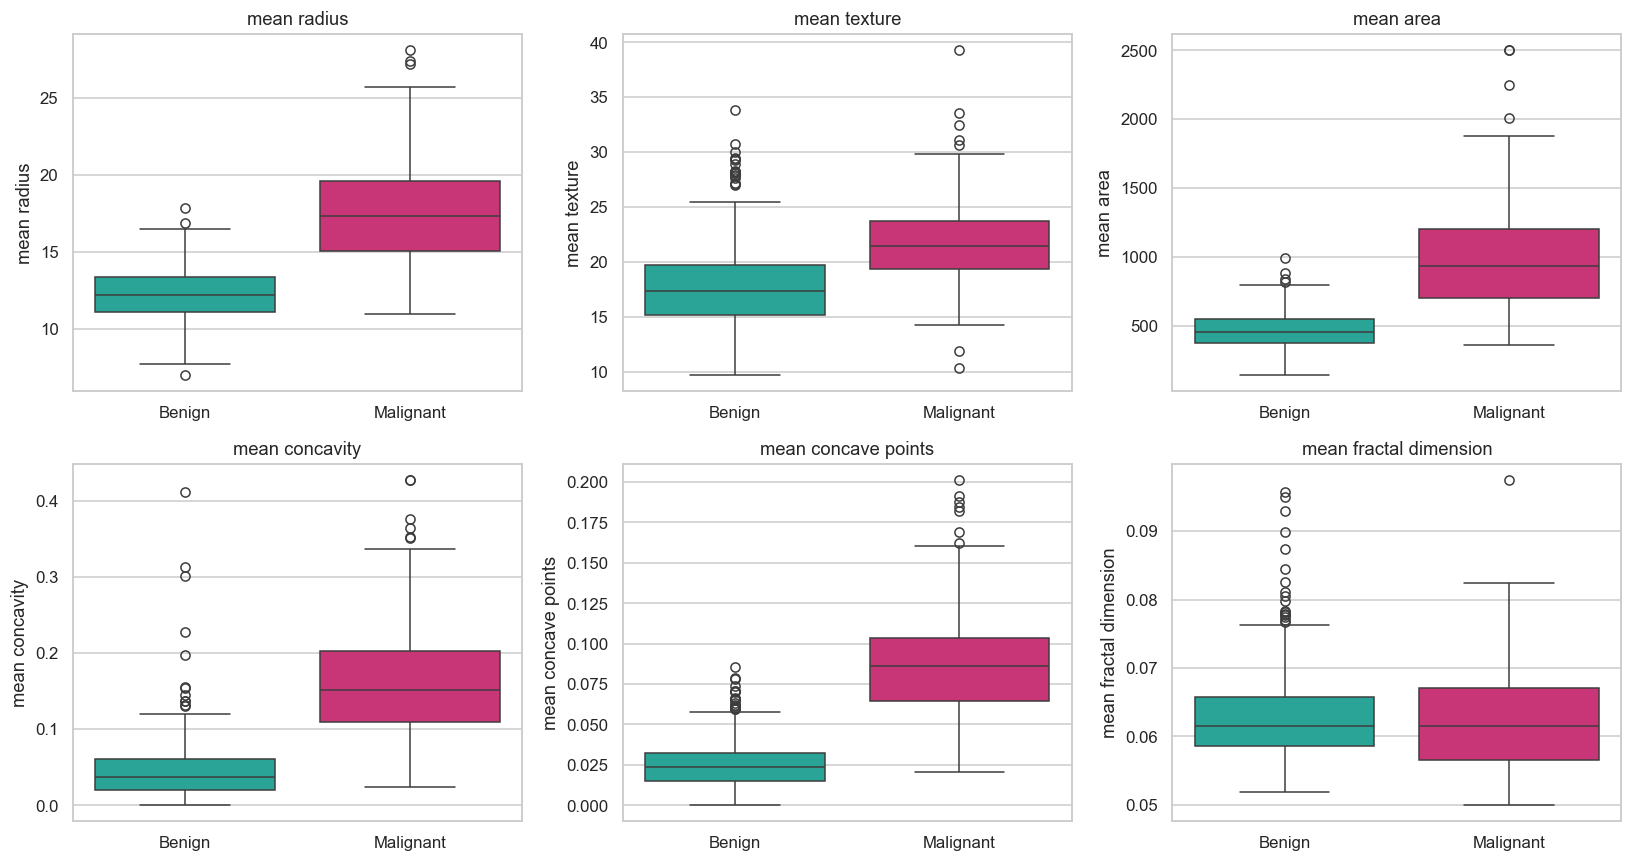

In [34]:
selected = ["mean radius", "mean texture", "mean area",
            "mean concavity", "mean concave points", "mean fractal dimension"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), selected):
    sns.boxplot(data=df, x="target_label", y=col, order=order,
                palette=COLORS, hue="target_label", legend=False, ax=ax)
    ax.set_xlabel("")
    ax.set_title(col)
plt.tight_layout()
plt.show()

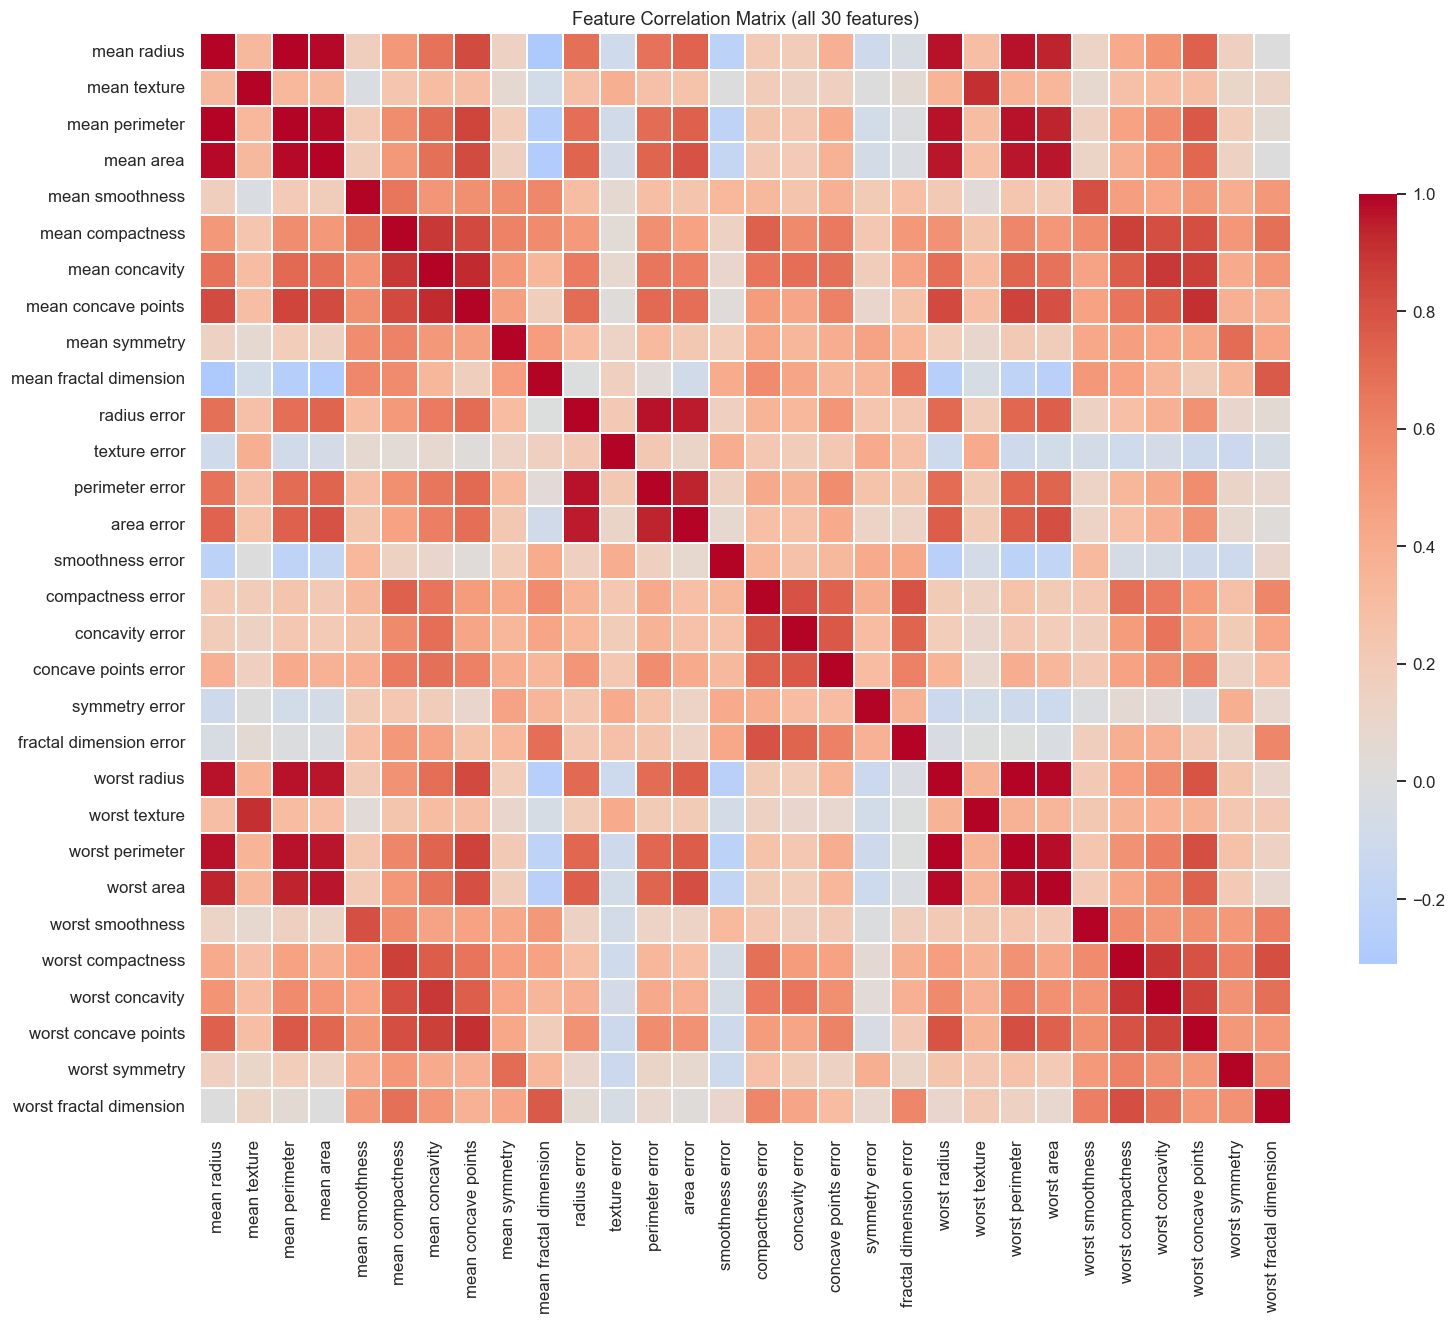

In [35]:
corr = features.corr()

plt.figure(figsize=(16, 13))
sns.heatmap(corr, cmap="coolwarm", center=0, square=True,
            linewidths=0.3, cbar_kws={"shrink": 0.7})
plt.title("Feature Correlation Matrix (all 30 features)")
plt.show()

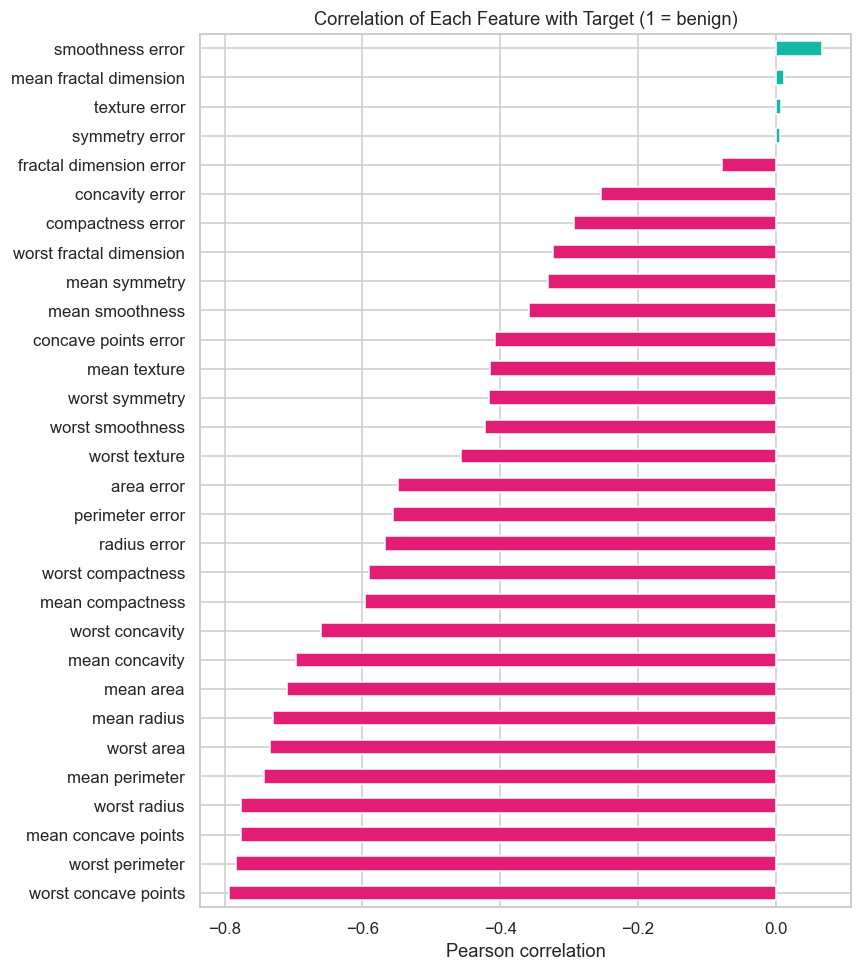

Strongest 5 (most negative = higher value -> more malignant):
worst concave points   -0.794
worst perimeter        -0.783
mean concave points    -0.777
worst radius           -0.776
mean perimeter         -0.743
dtype: float64


In [36]:
target_corr = features.corrwith(df["target"]).sort_values()

fig, ax = plt.subplots(figsize=(8, 9))
target_corr.plot(kind="barh", color=["#e11d74" if v < 0 else "#14b8a6" for v in target_corr], ax=ax)
ax.set_title("Correlation of Each Feature with Target (1 = benign)")
ax.set_xlabel("Pearson correlation")
plt.tight_layout()
plt.show()

print("Strongest 5 (most negative = higher value -> more malignant):")
print(target_corr.head(5).round(3))

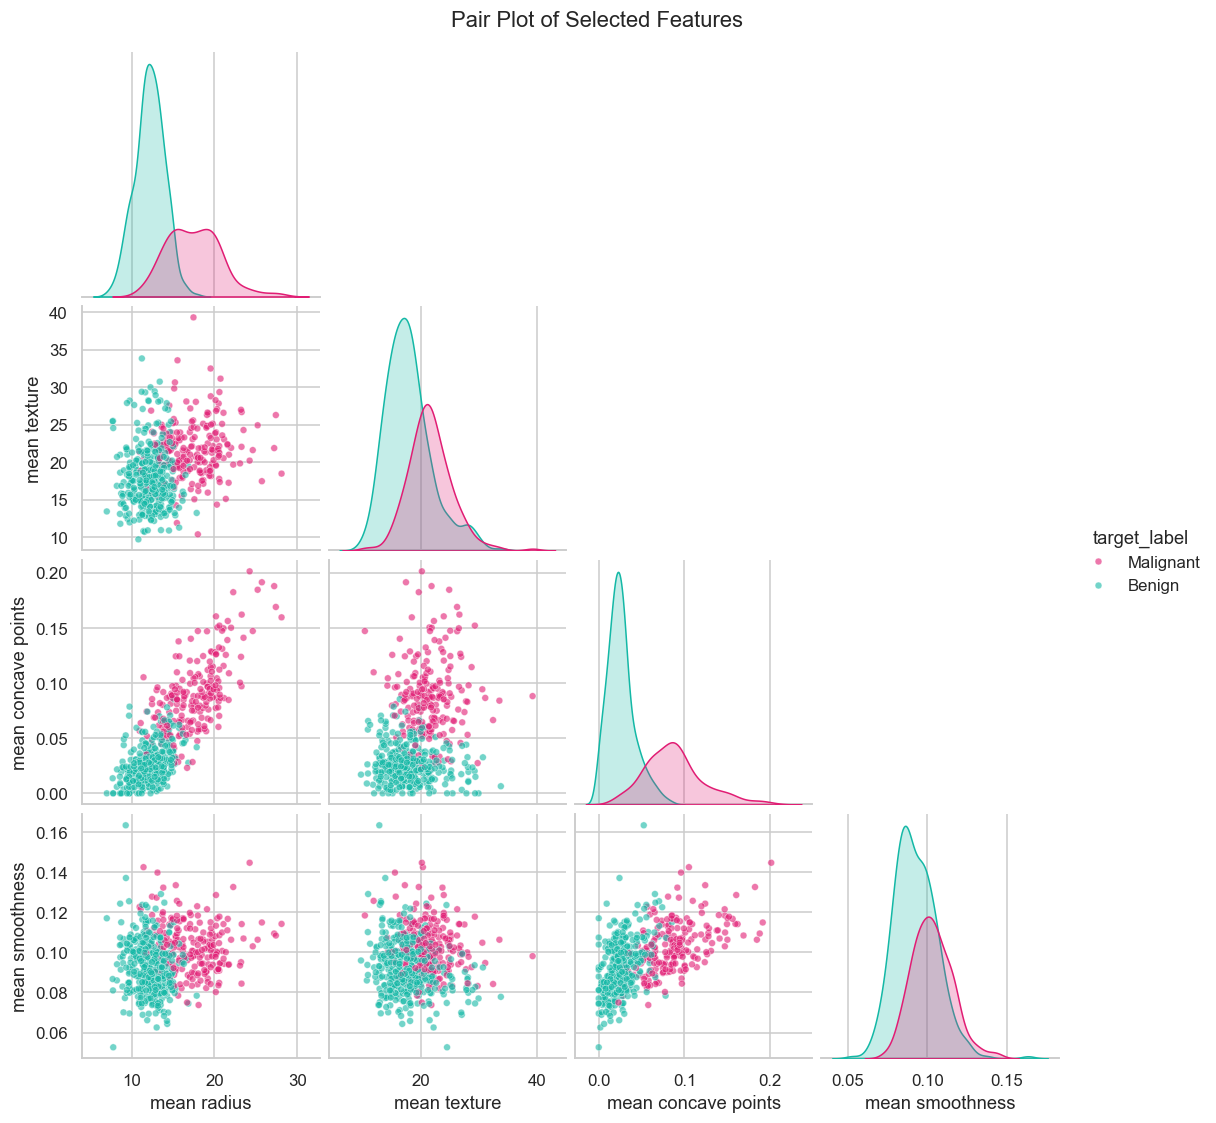

In [37]:
pair_cols = ["mean radius", "mean texture", "mean concave points", "mean smoothness"]
g = sns.pairplot(df, vars=pair_cols, hue="target_label", palette=COLORS,
                 corner=True, plot_kws={"alpha": 0.6, "s": 20})
g.figure.suptitle("Pair Plot of Selected Features", y=1.02)
plt.show()

In [38]:
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
pairs = (upper.stack()
              .rename("correlation")
              .reset_index()
              .rename(columns={"level_0": "feature_1", "level_1": "feature_2"}))
high = pairs[pairs["correlation"].abs() > 0.95].sort_values("correlation", ascending=False)

print("Number of feature pairs with |correlation| > 0.95:", len(high))
display(high.round(3))

Number of feature pairs with |correlation| > 0.95: 15


,feature_1,feature_2,correlation
1,mean radius,mean perimeter,0.998
391,worst radius,worst perimeter,0.994
2,mean radius,mean area,0.987
57,mean perimeter,mean area,0.987
392,worst radius,worst area,0.984
407,worst perimeter,worst area,0.978
246,radius error,perimeter error,0.973
76,mean perimeter,worst perimeter,0.970
19,mean radius,worst radius,0.970
74,mean perimeter,worst radius,0.969


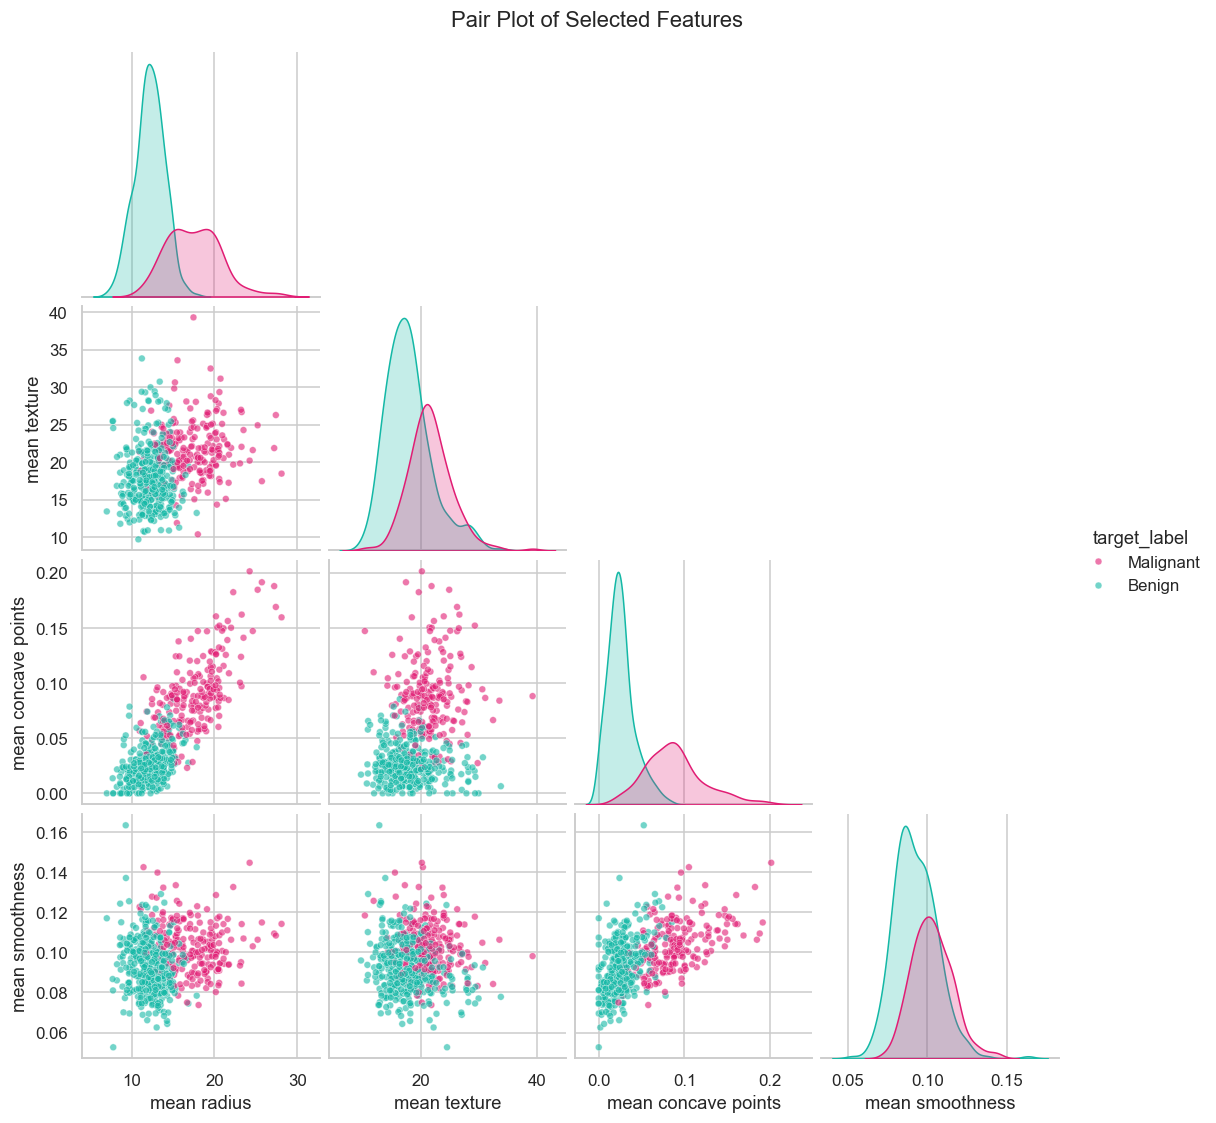

In [39]:
pair_cols = ["mean radius", "mean texture", "mean concave points", "mean smoothness"]
g = sns.pairplot(df, vars=pair_cols, hue="target_label", palette=COLORS,
                 corner=True, plot_kws={"alpha": 0.6, "s": 20})
g.figure.suptitle("Pair Plot of Selected Features", y=1.02)
plt.show()


In [40]:
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
pairs = (upper.stack()
              .rename("correlation")
              .reset_index()
              .rename(columns={"level_0": "feature_1", "level_1": "feature_2"}))
high = pairs[pairs["correlation"].abs() > 0.95].sort_values("correlation", ascending=False)

print("Number of feature pairs with |correlation| > 0.95:", len(high))
display(high.round(3))

Number of feature pairs with |correlation| > 0.95: 15


,feature_1,feature_2,correlation
1,mean radius,mean perimeter,0.998
391,worst radius,worst perimeter,0.994
2,mean radius,mean area,0.987
57,mean perimeter,mean area,0.987
392,worst radius,worst area,0.984
407,worst perimeter,worst area,0.978
246,radius error,perimeter error,0.973
76,mean perimeter,worst perimeter,0.970
19,mean radius,worst radius,0.970
74,mean perimeter,worst radius,0.969


In [41]:
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42

# X contains ONLY the 30 feature columns, never 'target' or 'target_label'
X = df[feature_columns]
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,               # keep the same class ratio in both sets
    random_state=RANDOM_STATE # reproducible split
)

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("\nTrain class counts:\n", y_train.value_counts().sort_index())
print("\nTest class counts:\n", y_test.value_counts().sort_index())
print("\nTrain malignant %:", round((y_train == 0).mean() * 100, 1))
print("Test malignant %: ", round((y_test == 0).mean() * 100, 1))

# Leakage guard
assert "target" not in X.columns and "target_label" not in X.columns
assert set(X_train.index).isdisjoint(set(X_test.index))

X_train: (455, 30) | X_test: (114, 30)

Train class counts:
 target
0    170
1    285
Name: count, dtype: int64

Test class counts:
 target
0    42
1    72
Name: count, dtype: int64

Train malignant %: 37.4
Test malignant %:  36.8


In [42]:
from sklearn.preprocessing import StandardScaler

# WRONG way (for learning only): scaling before splitting uses test-set statistics
# scaler.fit(X)  # <- would let the test set influence the mean and std

# RIGHT way: fit on training data only
scaler = StandardScaler().fit(X_train)
print("Scaler learned means from TRAIN only. First 3:", scaler.mean_[:3].round(3))
print("Means if computed on ALL data (leaky):        ", X.mean().values[:3].round(3))

Scaler learned means from TRAIN only. First 3: [14.067 19.247 91.557]
Means if computed on ALL data (leaky):         [14.127 19.29  91.969]


In [43]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

def make_pipeline(estimator):
    return Pipeline([("scaler", StandardScaler()), ("model", estimator)])

models = {
    "Logistic Regression": make_pipeline(LogisticRegression(max_iter=5000, random_state=RANDOM_STATE)),
    "SVM (RBF)":           make_pipeline(SVC(probability=True, random_state=RANDOM_STATE)),
    "Random Forest":       make_pipeline(RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE)),
    "KNN":                 make_pipeline(KNeighborsClassifier()),
    "Decision Tree":       make_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE)),
    "Gradient Boosting":   make_pipeline(GradientBoostingClassifier(random_state=RANDOM_STATE)),
}
print("Models defined:", list(models))

Models defined: ['Logistic Regression', 'SVM (RBF)', 'Random Forest', 'KNN', 'Decision Tree', 'Gradient Boosting']


In [44]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer, recall_score, precision_score, f1_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

scoring = {
    "accuracy":            "accuracy",
    "malignant_precision": make_scorer(precision_score, pos_label=0),
    "malignant_recall":    make_scorer(recall_score,    pos_label=0),
    "malignant_f1":        make_scorer(f1_score,        pos_label=0),
    "roc_auc":             "roc_auc",
}

rows = []
for name, pipe in models.items():
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    rows.append({
        "model": name,
        **{m: res[f"test_{m}"].mean() for m in scoring},
        "recall_std": res["test_malignant_recall"].std(),
    })

cv_results = (pd.DataFrame(rows)
                .set_index("model")
                .sort_values("malignant_recall", ascending=False)
                .round(4))
display(cv_results)

,accuracy,malignant_precision,malignant_recall,malignant_f1,roc_auc,recall_std
model,,,,,,
Logistic Regression,0.9780,0.9770,0.9647,0.9703,0.9959,0.0288
Random Forest,0.9648,0.9498,0.9588,0.9533,0.9902,0.0353
SVM (RBF),0.9692,0.9649,0.9529,0.9583,0.9956,0.0399
Gradient Boosting,0.9516,0.9365,0.9353,0.9353,0.9918,0.0288
KNN,0.9626,0.9707,0.9294,0.9490,0.9882,0.0235
Decision Tree,0.9165,0.8632,0.9235,0.8919,0.9179,0.0353


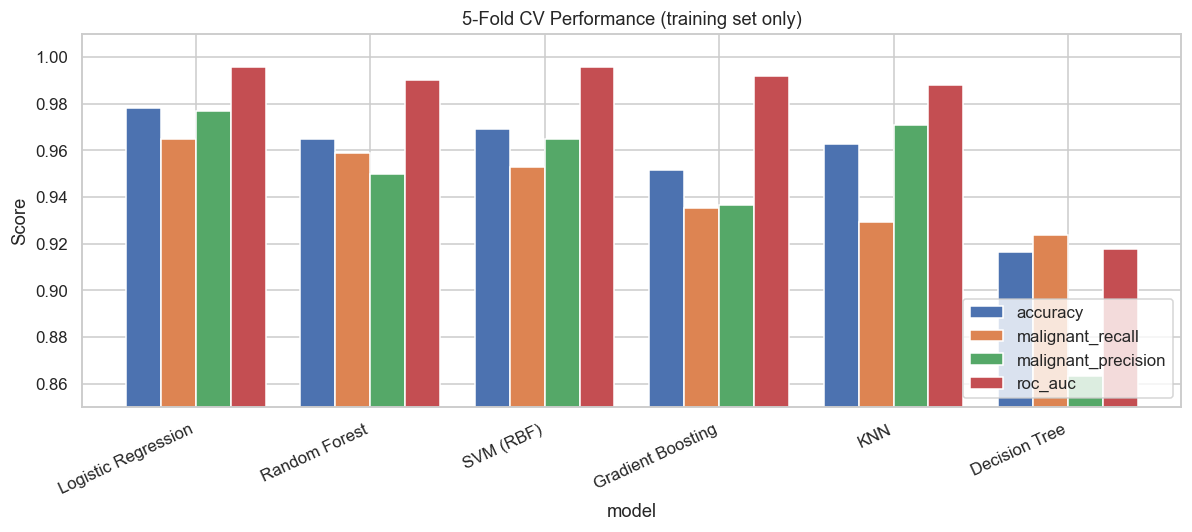

In [45]:
cv_results[["accuracy", "malignant_recall", "malignant_precision", "roc_auc"]].plot(
    kind="bar", figsize=(11, 5), width=0.8)
plt.title("5-Fold CV Performance (training set only)")
plt.ylabel("Score")
plt.ylim(0.85, 1.01)
plt.xticks(rotation=25, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [46]:
print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("Train malignant:", (y_train == 0).sum(), "| Test malignant:", (y_test == 0).sum())

X_train: (455, 30) | X_test: (114, 30)
Train malignant: 170 | Test malignant: 42


In [47]:
from sklearn.model_selection import GridSearchCV

param_grids = {
    "Logistic Regression": {
        "model__C": [0.01, 0.1, 1, 10, 100],
    },
    "SVM (RBF)": {
        "model__C": [0.1, 1, 10, 100],
        "model__gamma": ["scale", 0.01, 0.001],
    },
    "Random Forest": {
        "model__n_estimators": [200, 400],
        "model__max_depth": [None, 5, 10],
        "model__min_samples_leaf": [1, 2, 4],
    },
    "Gradient Boosting": {
        "model__n_estimators": [100, 200],
        "model__learning_rate": [0.05, 0.1],
        "model__max_depth": [2, 3],
    },
}

tuned = {}
tuning_rows = []

for name, grid in param_grids.items():
    gs = GridSearchCV(
        models[name], grid,
        cv=cv, scoring=scoring, refit="malignant_f1",
        n_jobs=1, return_train_score=False,
    )
    gs.fit(X_train, y_train)          # X_train only; the test set is never used
    tuned[name] = gs.best_estimator_
    i = gs.best_index_
    tuning_rows.append({
        "model": name,
        "best_params": gs.best_params_,
        "accuracy": gs.cv_results_["mean_test_accuracy"][i],
        "malignant_precision": gs.cv_results_["mean_test_malignant_precision"][i],
        "malignant_recall": gs.cv_results_["mean_test_malignant_recall"][i],
        "malignant_f1": gs.cv_results_["mean_test_malignant_f1"][i],
        "roc_auc": gs.cv_results_["mean_test_roc_auc"][i],
        "recall_std": gs.cv_results_["std_test_malignant_recall"][i],
    })
    print("done:", name)

tuning_results = (pd.DataFrame(tuning_rows)
                    .set_index("model")
                    .sort_values("malignant_f1", ascending=False))
pd.set_option("display.max_colwidth", 120)
display(tuning_results.round(4))

done: Logistic Regression
done: SVM (RBF)
done: Random Forest
done: Gradient Boosting


,best_params,accuracy,malignant_precision,malignant_recall,malignant_f1,roc_auc,recall_std
model,,,,,,,
Logistic Regression,{'model__C': 0.1},0.9824,0.9941,0.9588,0.9760,0.9951,0.0144
SVM (RBF),"{'model__C': 10, 'model__gamma': 0.01}",0.9758,0.9820,0.9529,0.9668,0.9964,0.0399
Gradient Boosting,"{'model__learning_rate': 0.1, 'model__max_depth': 2, 'model__n_estimators': 200}",0.9670,0.9595,0.9529,0.9557,0.9929,0.0300
Random Forest,"{'model__max_depth': None, 'model__min_samples_leaf': 1, 'model__n_estimators': 200}",0.9626,0.9493,0.9529,0.9503,0.9894,0.0300


In [48]:
display(tuning_results.round(4))

,best_params,accuracy,malignant_precision,malignant_recall,malignant_f1,roc_auc,recall_std
model,,,,,,,
Logistic Regression,{'model__C': 0.1},0.9824,0.9941,0.9588,0.9760,0.9951,0.0144
SVM (RBF),"{'model__C': 10, 'model__gamma': 0.01}",0.9758,0.9820,0.9529,0.9668,0.9964,0.0399
Gradient Boosting,"{'model__learning_rate': 0.1, 'model__max_depth': 2, 'model__n_estimators': 200}",0.9670,0.9595,0.9529,0.9557,0.9929,0.0300
Random Forest,"{'model__max_depth': None, 'model__min_samples_leaf': 1, 'model__n_estimators': 200}",0.9626,0.9493,0.9529,0.9503,0.9894,0.0300


In [49]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report,
                             roc_curve)

shortlist = ["Logistic Regression", "SVM (RBF)", "Random Forest"]
test_rows, test_preds, test_scores = [], {}, {}

for name in shortlist:
    pipe = tuned[name]                       # already fitted on X_train
    y_pred = pipe.predict(X_test)
    p_benign = pipe.predict_proba(X_test)[:, 1]   # column 1 = class 1 = benign
    test_preds[name], test_scores[name] = y_pred, p_benign
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred, labels=[0, 1]).ravel()
    # Here class 0 (malignant) is the "positive" class of interest:
    #   tn = malignant correctly found, fp(0->1) = malignant missed (false negative)
    test_rows.append({
        "model": name,
        "accuracy": accuracy_score(y_test, y_pred),
        "malignant_precision": precision_score(y_test, y_pred, pos_label=0),
        "malignant_recall": recall_score(y_test, y_pred, pos_label=0),
        "malignant_f1": f1_score(y_test, y_pred, pos_label=0),
        "roc_auc": roc_auc_score(y_test, p_benign),
        "malignant_missed (FN)": int(fp),
        "benign_flagged_malignant (FP)": int(fn),
    })

test_results = pd.DataFrame(test_rows).set_index("model").round(4)
display(test_results)

for name in shortlist:
    print("\n" + "=" * 60, "\n" + name)
    print(classification_report(y_test, test_preds[name],
                                target_names=["malignant", "benign"], digits=3))

,accuracy,malignant_precision,malignant_recall,malignant_f1,roc_auc,malignant_missed (FN),benign_flagged_malignant (FP)
model,,,,,,,
Logistic Regression,0.9737,0.9756,0.9524,0.9639,0.9957,2,1
SVM (RBF),0.9825,0.9762,0.9762,0.9762,0.9977,1,1
Random Forest,0.9561,0.9512,0.9286,0.9398,0.9932,3,2



Logistic Regression
              precision    recall  f1-score   support

   malignant      0.976     0.952     0.964        42
      benign      0.973     0.986     0.979        72

    accuracy                          0.974       114
   macro avg      0.974     0.969     0.972       114
weighted avg      0.974     0.974     0.974       114


SVM (RBF)
              precision    recall  f1-score   support

   malignant      0.976     0.976     0.976        42
      benign      0.986     0.986     0.986        72

    accuracy                          0.982       114
   macro avg      0.981     0.981     0.981       114
weighted avg      0.982     0.982     0.982       114


Random Forest
              precision    recall  f1-score   support

   malignant      0.951     0.929     0.940        42
      benign      0.959     0.972     0.966        72

    accuracy                          0.956       114
   macro avg      0.955     0.950     0.953       114
weighted avg      0.956    

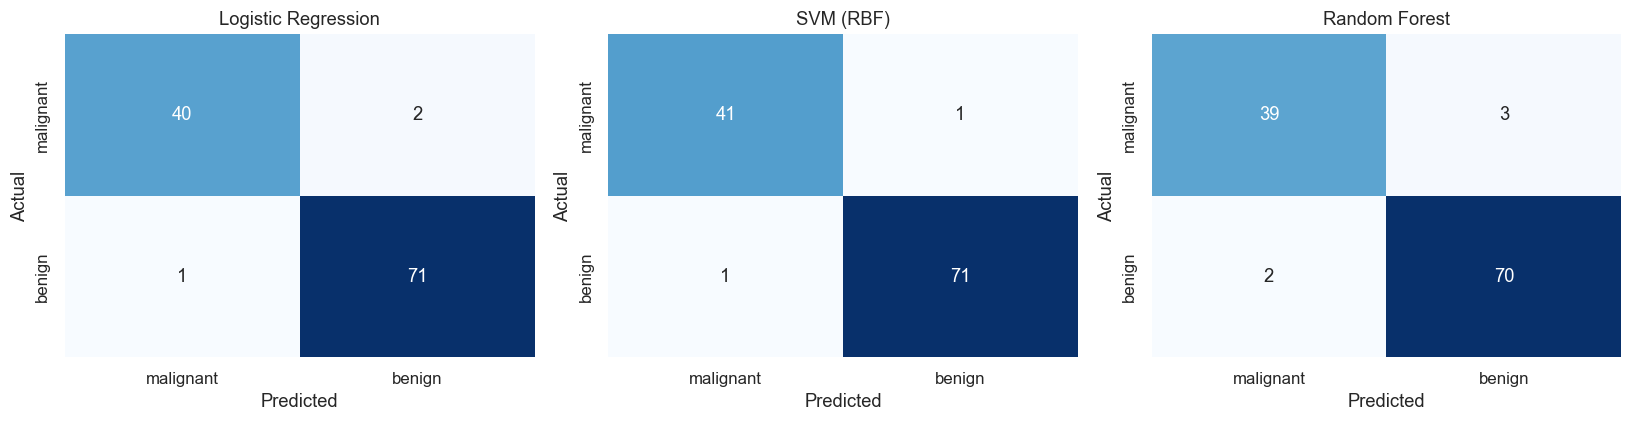

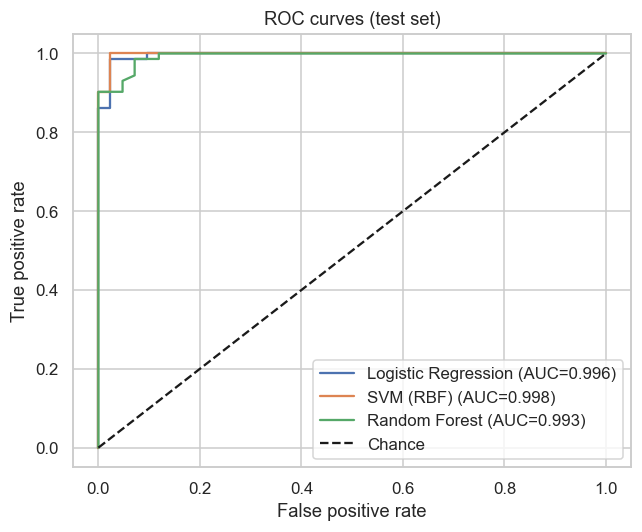

In [50]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, name in zip(axes, shortlist):
    cm = confusion_matrix(y_test, test_preds[name], labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["malignant", "benign"], yticklabels=["malignant", "benign"])
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 5))
for name in shortlist:
    fpr, tpr, _ = roc_curve(y_test, test_scores[name])
    auc = roc_auc_score(y_test, test_scores[name])
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Chance")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC curves (test set)")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

Brier score (lower is better): 0.0279


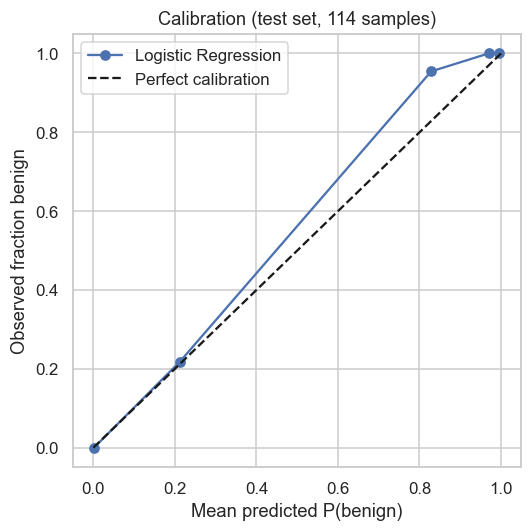

In [51]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

FINAL_MODEL_NAME = "Logistic Regression"   # change only if the test table justifies it

final_pipeline = tuned[FINAL_MODEL_NAME]
p_benign = final_pipeline.predict_proba(X_test)[:, 1]

print("Brier score (lower is better):", round(brier_score_loss(y_test, p_benign), 4))
frac_pos, mean_pred = calibration_curve(y_test, p_benign, n_bins=5, strategy="quantile")

plt.figure(figsize=(5, 5))
plt.plot(mean_pred, frac_pos, "o-", label=FINAL_MODEL_NAME)
plt.plot([0, 1], [0, 1], "k--", label="Perfect calibration")
plt.xlabel("Mean predicted P(benign)")
plt.ylabel("Observed fraction benign")
plt.title("Calibration (test set, 114 samples)")
plt.legend()
plt.tight_layout()
plt.show()

In [52]:
import json, platform, datetime
import joblib

model_dir = project_root / "backend" / "app" / "model"
model_dir.mkdir(parents=True, exist_ok=True)

pipeline_path = model_dir / "breast_cancer_pipeline.joblib"
metadata_path = model_dir / "model_metadata.json"

joblib.dump(final_pipeline, pipeline_path)

def clean(d):
    return {k: (float(v) if isinstance(v, (int, float, np.floating, np.integer)) else v)
            for k, v in d.items()}

metadata = {
    "model_name": FINAL_MODEL_NAME,
    "model_version": "1.0.0",
    "trained_at_utc": datetime.datetime.now(datetime.timezone.utc).isoformat(timespec="seconds"),
    "python_version": platform.python_version(),
    "sklearn_version": sklearn.__version__,
    "numpy_version": np.__version__,
    "pandas_version": pd.__version__,
    "dataset": "Wisconsin Diagnostic Breast Cancer (via scikit-learn load_breast_cancer)",
    "n_train": int(len(X_train)),
    "n_test": int(len(X_test)),
    "random_state": RANDOM_STATE,
    "feature_names": feature_columns,
    "classes": {"0": "malignant", "1": "benign"},
    "best_params": {k: (v if v is None or isinstance(v, str) else float(v))
                    for k, v in tuned[FINAL_MODEL_NAME].get_params().items()
                    if k in ("model__C", "model__gamma")},
    "cv_metrics_train": clean(tuning_results.loc[FINAL_MODEL_NAME].drop("best_params").to_dict()),
    "test_metrics": clean(test_results.loc[FINAL_MODEL_NAME].to_dict()),
}

with open(metadata_path, "w") as f:
    json.dump(metadata, f, indent=2)

print("Saved:", pipeline_path, f"({pipeline_path.stat().st_size/1024:.1f} KB)")
print("Saved:", metadata_path)

Saved: C:\breastcancer-ai\backend\app\model\breast_cancer_pipeline.joblib (3.0 KB)
Saved: C:\breastcancer-ai\backend\app\model\model_metadata.json


In [53]:
reloaded = joblib.load(pipeline_path)
meta = json.load(open(metadata_path))

# 1. Same predictions and probabilities as the original
assert np.array_equal(reloaded.predict(X_test), final_pipeline.predict(X_test))
assert np.allclose(reloaded.predict_proba(X_test), final_pipeline.predict_proba(X_test))

# 2. Feature order matches what training used
assert meta["feature_names"] == list(X_train.columns) == feature_columns
assert list(reloaded.feature_names_in_) == feature_columns

# 3. Single-record test, as the API will do it (dict -> one-row DataFrame)
sample = X_test.iloc[[0]]
record = sample.iloc[0].to_dict()
row = pd.DataFrame([record], columns=meta["feature_names"])
pred = int(reloaded.predict(row)[0])
proba = reloaded.predict_proba(row)[0]

print("Predicted class:", pred, "->", meta["classes"][str(pred)])
print("P(malignant), P(benign):", proba.round(4))
print("Pipeline steps:", [s[0] for s in reloaded.steps])
print("All Phase 2 verification checks passed.")

Predicted class: 0 -> malignant
P(malignant), P(benign): [1. 0.]
Pipeline steps: ['scaler', 'model']
All Phase 2 verification checks passed.


In [54]:
import json
from pathlib import Path

project_root = Path.cwd().parent   # notebook runs from notebooks/
meta_path = project_root / "backend" / "app" / "model" / "model_metadata.json"
print("Exists:", meta_path.exists(), "|", meta_path)

meta = json.load(open(meta_path))
print("python :", meta["python_version"])
print("sklearn:", meta["sklearn_version"])
print("numpy  :", meta["numpy_version"])
print("pandas :", meta["pandas_version"])
print("model  :", meta["model_name"], "| best_params:", meta["best_params"])
print("\nCV metrics (train):", meta["cv_metrics_train"])
print("\nTEST metrics:", meta["test_metrics"])

Exists: True | c:\breastcancer-ai\backend\app\model\model_metadata.json
python : 3.10.0
sklearn: 1.7.2
numpy  : 2.2.6
pandas : 2.3.3
model  : Logistic Regression | best_params: {'model__C': 0.1}

CV metrics (train): {'accuracy': 0.9824175824175825, 'malignant_precision': 0.9941176470588236, 'malignant_recall': 0.9588235294117646, 'malignant_f1': 0.97602628568388, 'roc_auc': 0.9951496388028895, 'recall_std': 0.014408763192842228}

TEST metrics: {'accuracy': 0.9737, 'malignant_precision': 0.9756, 'malignant_recall': 0.9524, 'malignant_f1': 0.9639, 'roc_auc': 0.9957, 'malignant_missed (FN)': 2.0, 'benign_flagged_malignant (FP)': 1.0}


In [55]:
import json, pandas as pd
row = pd.read_csv(r"C:\breastcancer-ai\data\raw\wdbc.csv").iloc[0]
cols = [c for c in row.index if c not in ("target", "target_label")]
print(json.dumps({c.replace(" ", "_"): float(row[c]) for c in cols}, indent=2))

{
  "mean_radius": 17.99,
  "mean_texture": 10.38,
  "mean_perimeter": 122.8,
  "mean_area": 1001.0,
  "mean_smoothness": 0.1184,
  "mean_compactness": 0.2776,
  "mean_concavity": 0.3001,
  "mean_concave_points": 0.1471,
  "mean_symmetry": 0.2419,
  "mean_fractal_dimension": 0.07871,
  "radius_error": 1.095,
  "texture_error": 0.9053,
  "perimeter_error": 8.589,
  "area_error": 153.4,
  "smoothness_error": 0.006399,
  "compactness_error": 0.04904,
  "concavity_error": 0.05373,
  "concave_points_error": 0.01587,
  "symmetry_error": 0.03003,
  "fractal_dimension_error": 0.006193,
  "worst_radius": 25.38,
  "worst_texture": 17.33,
  "worst_perimeter": 184.6,
  "worst_area": 2019.0,
  "worst_smoothness": 0.1622,
  "worst_compactness": 0.6656,
  "worst_concavity": 0.7119,
  "worst_concave_points": 0.2654,
  "worst_symmetry": 0.4601,
  "worst_fractal_dimension": 0.1189
}


In [56]:
import json, pandas as pd
from pathlib import Path

row = pd.read_csv(r"C:\breastcancer-ai\data\raw\wdbc.csv").iloc[0]
cols = [c for c in row.index if c not in ("target", "target_label")]
payload = {c.replace(" ", "_"): float(row[c]) for c in cols}

out = Path(r"C:\breastcancer-ai\backend\tests\sample_request.json")
out.write_text(json.dumps(payload, indent=2), encoding="utf-8")
print("Saved:", out, "| fields:", len(payload))

Saved: C:\breastcancer-ai\backend\tests\sample_request.json | fields: 30


In [57]:
import json
from sklearn.metrics import roc_curve, confusion_matrix

def r4(x):
    return round(float(x), 4)

models_out = []
for name in shortlist:
    t = test_results.loc[name]
    cv_row = tuning_results.loc[name]
    cm = confusion_matrix(y_test, test_preds[name], labels=[0, 1])
    fpr, tpr, _ = roc_curve(y_test, test_scores[name])
    models_out.append({
        "name": name,
        "test": {
            "accuracy": r4(t["accuracy"]),
            "precision": r4(t["malignant_precision"]),
            "recall": r4(t["malignant_recall"]),
            "f1": r4(t["malignant_f1"]),
            "roc_auc": r4(t["roc_auc"]),
        },
        "cv": {
            "accuracy": r4(cv_row["accuracy"]),
            "recall": r4(cv_row["malignant_recall"]),
            "f1": r4(cv_row["malignant_f1"]),
            "roc_auc": r4(cv_row["roc_auc"]),
        },
        # rows = actual, columns = predicted, order [malignant, benign]
        "confusion_matrix": cm.tolist(),
        "roc_curve": [{"fpr": r4(a), "tpr": r4(b)} for a, b in zip(fpr, tpr)],
    })

# Standardised coefficients of the final model (class 1 = benign, so we flip the sign)
final = tuned["Logistic Regression"]
coefs = final.named_steps["model"].coef_[0]
top = sorted(zip(feature_columns, coefs), key=lambda p: abs(p[1]), reverse=True)[:10]
features_out = [{"feature": f, "toward_malignant": r4(-c)} for f, c in top]

insights = {
    "final_model": "Logistic Regression",
    "dataset": {
        "name": "Wisconsin Diagnostic Breast Cancer (via scikit-learn)",
        "n_total": int(len(X)),
        "n_train": int(len(X_train)),
        "n_test": int(len(X_test)),
        "test_malignant": int((y_test == 0).sum()),
        "test_benign": int((y_test == 1).sum()),
    },
    "procedure": (
        "Models were tuned with 5-fold stratified cross-validation on the training set only. "
        "The 114-row test set was used once to report the test metrics. "
        "Malignant is treated as the positive class for precision, recall and F1."
    ),
    "models": models_out,
    "top_features": features_out,
}

out_dir = project_root / "frontend" / "src" / "data"
out_dir.mkdir(parents=True, exist_ok=True)
out_path = out_dir / "model_insights.json"
out_path.write_text(json.dumps(insights, indent=2), encoding="utf-8")

print("Saved:", out_path, f"({out_path.stat().st_size / 1024:.1f} KB)")
for m in models_out:
    print(m["name"], "| test:", m["test"], "| matrix:", m["confusion_matrix"])
print("Top features toward malignant:", features_out[:3])

Saved: c:\breastcancer-ai\frontend\src\data\model_insights.json (5.3 KB)
Logistic Regression | test: {'accuracy': 0.9737, 'precision': 0.9756, 'recall': 0.9524, 'f1': 0.9639, 'roc_auc': 0.9957} | matrix: [[40, 2], [1, 71]]
SVM (RBF) | test: {'accuracy': 0.9825, 'precision': 0.9762, 'recall': 0.9762, 'f1': 0.9762, 'roc_auc': 0.9977} | matrix: [[41, 1], [1, 71]]
Random Forest | test: {'accuracy': 0.9561, 'precision': 0.9512, 'recall': 0.9286, 'f1': 0.9398, 'roc_auc': 0.9932} | matrix: [[39, 3], [2, 70]]
Top features toward malignant: [{'feature': np.str_('worst texture'), 'toward_malignant': 0.5635}, {'feature': np.str_('worst radius'), 'toward_malignant': 0.509}, {'feature': np.str_('worst concave points'), 'toward_malignant': 0.5078}]
